# Career Value of NFL Combine Outliers Relative to Draft Position

Santiago Criado, Phu Duong, Sri Indla, and Steven Goetz

COS 424: Reasoning with Data · Princeton University

We ask whether prospects with unusual size or athleticism are more likely to be drafted and whether they tend to go earlier. Among drafted players, we examine whether outliers produce more career value than expected for their pick, position, and draft class.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

from utils import detect, features, outcomes, plots, prepare, summaries

plots.use_style()

## 1. Data

We use an October 2026 snapshot of three [nflverse](https://github.com/nflverse/nflverse-data) tables.

| Table | Information used |
| --- | --- |
| Combine | Height, weight, workout results, and draft information for prospects from 2000 to 2026 |
| Draft Picks | Draft year, overall pick, round, position, and career Weighted Approximate Value (WAV) |
| Players | NFL roster positions |

In [2]:
prepare.verify_snapshot()
raw = prepare.load_raw()
source_sizes = summaries.raw_overview(raw).rename(
    index={"combine": "Combine", "draft_picks": "Draft Picks", "players": "Players"},
    columns={"rows": "Rows", "columns": "Columns"},
)
display(source_sizes.rename_axis("Table"))

,Rows,Columns
Table,,
Combine,8968,18
Draft Picks,12927,36
Players,24844,39


### Sample construction

We link Combine records to the Draft Picks table by draft year and overall pick. The 2026 Combine records lack draft slots, so we match that class by exact player name. If several Combine records are linked to the same pick, we favor the record in the same position family as the draft pick.

We assign prospects to 11 position groups. For prospects listed only as offensive linemen, defensive linemen, or defensive backs, we use a more specific roster or draft position when available. Otherwise, we assign their position based on height or weight. We split outside linebackers by weight.

The size-and-speed score requires height, weight, and a 40-yard dash time, so we keep prospects with all three. We convert height to inches and exclude offensive linemen and linebackers whose listed weight falls outside the bounds for their position.

In [3]:
sample = prepare.build_sample(raw)
prospects = sample.prospects

print(f"We matched {sample.linked_by_name:,} prospects from {prepare.UNLINKED_CLASS} to draft picks by name.")
display(sample.log)

We matched 211 prospects from 2026 to draft picks by name.


,Step,Rows remaining,Removed
0,"Combine records, 2000–2026",8968,0
1,Resolve records linked to the same pick,8958,10
2,Keep prospects in 11 position groups,8528,430
3,"Require height, weight, and 40-yard dash time",7699,829
4,Apply position-specific weight filters,7690,9


### Sample characteristics

The scatterplot compares weight and 40-yard dash times across positions. Faster times appear higher on the vertical axis. The heatmap shows how often each drill is missing in the cleaned sample.

,Prospects,Drafted,Mean height (in),Mean weight (lb),Mean 40-yard dash (s),Mean drills per prospect
Position,,,,,,
QB,413,239,74.69,222.18,4.81,4.35
RB,716,424,70.42,213.12,4.55,4.47
WR,1156,708,72.74,201.01,4.51,4.36
TE,452,299,76.29,252.95,4.76,4.74
OT,608,440,77.64,315.40,5.23,4.76
IOL,722,433,75.82,311.02,5.26,4.86
DT,604,431,74.96,306.74,5.09,4.59
EDGE,826,604,75.52,263.24,4.78,4.66
LB,718,483,73.41,237.12,4.69,4.63


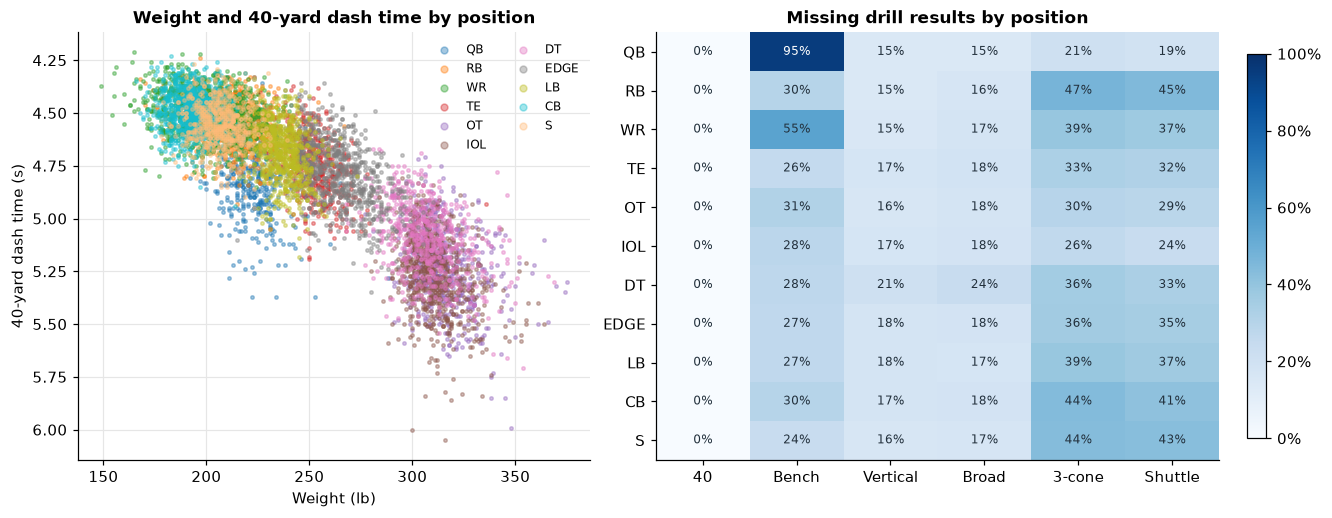

Of the 7,690 prospects in the sample, 5,081 were drafted.
Across the six drills, 23.7% of results are missing.


In [4]:
census = summaries.sample_census(prospects).rename(
    columns={
        "prospects": "Prospects",
        "drafted": "Drafted",
        "mean_ht": "Mean height (in)",
        "mean_wt": "Mean weight (lb)",
        "mean_forty": "Mean 40-yard dash (s)",
        "mean_drills": "Mean drills per prospect",
    }
)
display(census.round(2).rename_axis("Position"))
missing_drills = summaries.drill_missing_by_position(prospects)
plots.sample_overview(prospects, missing_drills)
plt.show()

n_drafted = prospects["drafted"].sum()
missing_share = prospects[prepare.DRILLS].isna().to_numpy().mean()
print(f"Of the {len(prospects):,} prospects in the sample, {n_drafted:,} were drafted.")
print(f"Across the six drills, {missing_share:.1%} of results are missing.")

## 2. Adjusting drill results for size and era

Within each position, we fit a regression for each drill using height, weight, weight squared, and Combine year. We add an indicator for the 2021 pro-day class and fit each regression using recorded results. We center and scale the residuals using their median and median absolute deviation. We reverse the sign for timed drills so that higher scores indicate better performances. We also scale height and weight within position.

A drill enters the full-workout score if at least 25% of the position group has a recorded result. We use iterative imputation to estimate missing results from the other measurements, then adjust those estimates using the same regression. Those estimates can affect the rankings.

To measure overall athleticism, we average each player's adjusted drill scores and standardize the average within position. The table shows the eight prospects with the highest adjusted 40-yard dash scores.

In [5]:
with threadpool_limits(limits=1):
    adjusted = features.adjust_drills(prospects)

display_columns = {
    "player_name": "Player",
    "season": "Combine year",
    "grp": "Position",
    "ht": "Height (in)",
    "wt": "Weight (lb)",
    "forty": "40-yard dash (s)",
    "adj_forty": "Adjusted 40 score",
}
fastest = summaries.fastest_for_size(adjusted)
fastest = fastest[list(display_columns)].rename(columns=display_columns)
display(fastest.set_index("Player").round(2))

,Combine year,Position,Height (in),Weight (lb),40-yard dash (s),Adjusted 40 score
Player,,,,,,
Bruce Campbell,2010,OT,78.0,314.0,4.75,3.20
Vernon Davis,2006,TE,75.0,254.0,4.38,3.16
Terron Armstead,2013,OT,77.0,306.0,4.71,3.03
Jordan Davis,2022,DT,78.0,341.0,4.78,2.96
Donte' Stallworth,2002,WR,72.0,197.0,4.22,2.94
Elton Brown,2005,IOL,77.0,329.0,4.93,2.94
Lane Johnson,2013,OT,78.0,303.0,4.72,2.89
Jayson Oweh,2021,EDGE,77.0,257.0,4.36,2.88


## 3. Identifying outliers

We use robust Mahalanobis distance to measure how unusual a player's combination of measurements is for his position. We estimate the center $\boldsymbol{\mu}$ and covariance $\boldsymbol{\Sigma}$ with the minimum covariance determinant estimator. The initial fit uses about 85% of the position group to limit the influence of extreme observations.

$$D^2(\mathbf{x}) = (\mathbf{x}-\boldsymbol{\mu})^\top \boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu})$$

We calculate two distances for each prospect. The size-and-speed score uses height, weight, and the adjusted 40-yard dash time. The full-workout score adds the other eligible drills. We convert both distances to percentiles within position, take the higher percentile for each player, then rank those values again. We flag players above the 95th percentile in that final ranking. Players with tied scores receive the average rank.

Within the flagged group, a player's athleticism score determines the category. Players at least 0.75 standard deviations above their position's mean are favorable outliers. Players at least 0.75 standard deviations below it are unfavorable outliers. We call the remaining flagged players unusual builds. Players at or below the cutoff make up the typical group.

In [6]:
with threadpool_limits(limits=1):
    scored = detect.score_prospects(adjusted)

counts = summaries.unicorn_counts(scored).rename(columns=plots.TYPE_LABEL)
display(counts.rename_axis(index="Position", columns=None))
print(f"The model flagged {scored['unicorn'].sum():,} prospects as outliers.")

,Favorable outlier,Unusual build,Unfavorable outlier,Typical
Position,,,,
QB,7,7,7,392
RB,5,14,18,679
WR,19,22,17,1098
TE,4,11,8,429
OT,6,13,12,577
IOL,9,14,13,686
DT,10,14,6,574
EDGE,14,14,13,785
LB,7,14,15,682


The model flagged 388 prospects as outliers.


### Checking the full-workout distances

The dashed line shows the chi-square reference for a multivariate normal model. The largest observed distances exceed that reference in each position shown. The orange line marks the 95th percentile of the observed full-workout distances. We use the ranks from both scores to flag outliers.

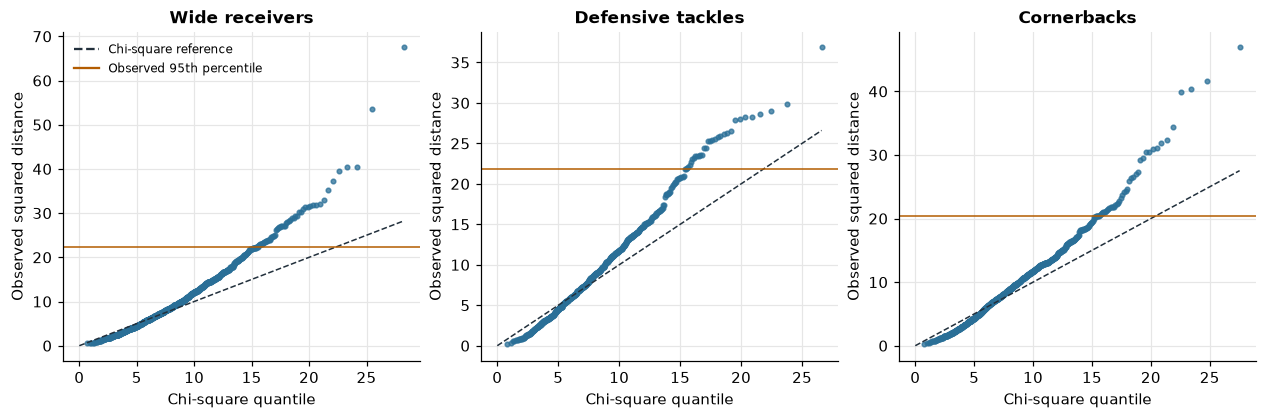

9.2% of full-workout distances exceeded the chi-square cutoff for the upper 2.5%.


In [7]:
plots.chi2_qq(scored)
plt.show()

reference_tail = 0.025
share_above = summaries.share_beyond_chi2(scored, tail=reference_tail)
print(
    f"{share_above:.1%} of full-workout distances exceeded the chi-square cutoff "
    f"for the upper {reference_tail:.1%}."
)

### Outliers by position

The panels show weight and 40-yard dash time for wide receivers, edge rushers, and cornerbacks. Faster times appear higher on the vertical axis. Some flagged players appear near the center of their group in these plots. The outlier score also uses height, other drills, and adjustments for size and era. The labels identify two of the highest-ranked outliers in each position.

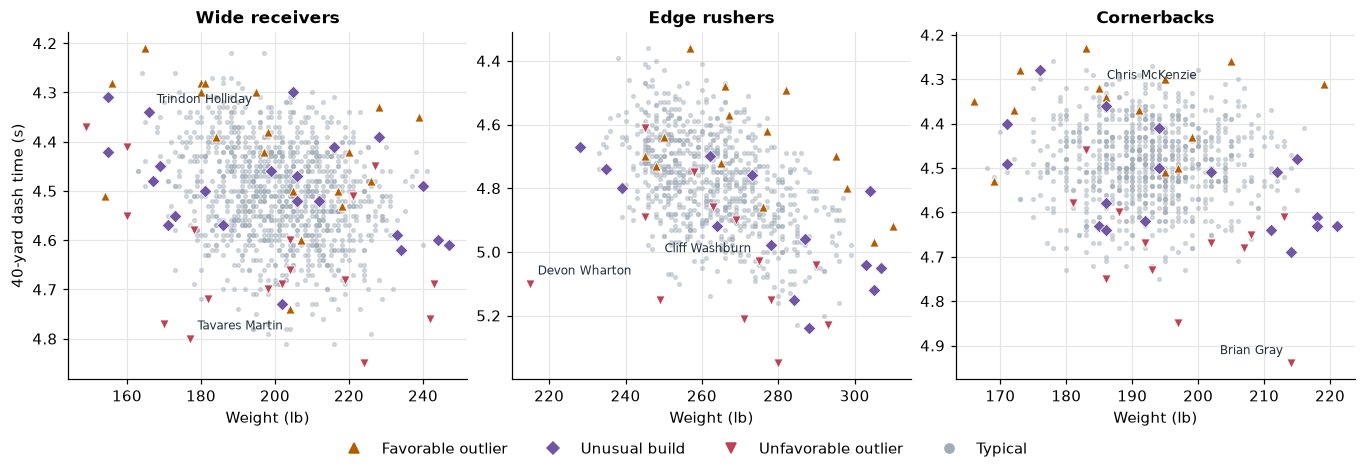

In [8]:
plots.unicorn_scatter(scored)
plt.show()

## 4. Draft selection

We compare draft rates and median picks for Combine classes from 2000 through 2022, the years covered by the career-value analysis. The draft rate uses all scored prospects. The median pick uses those who were drafted.

,Prospects,Drafted,Drafted (%),Median pick
Prospect group,,,,
Favorable outlier,90,79,87.8,72.0
Unusual build,141,87,61.7,99.0
Unfavorable outlier,132,37,28.0,162.0
Typical,6496,4323,66.5,108.0


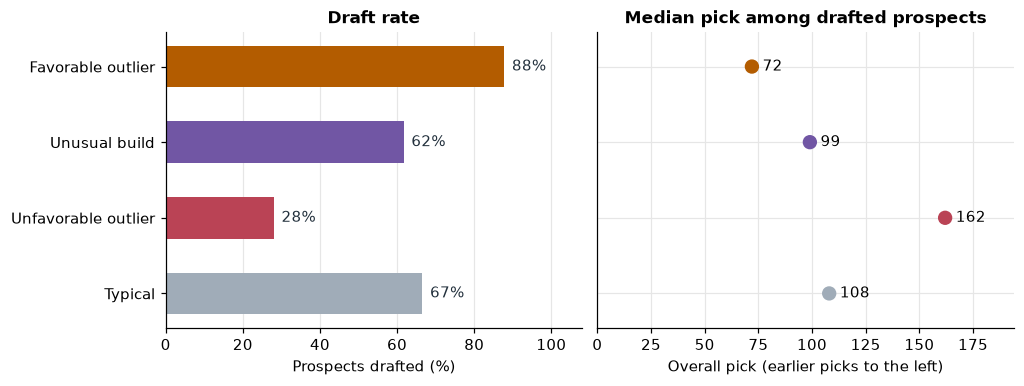

In [9]:
draft_sample = scored.loc[scored["season"].le(outcomes.LAST_DRAFT_CLASS)]
selection = outcomes.draft_selection(draft_sample).reindex(detect.TYPES)
selection_labels = {
    "prospects": "Prospects",
    "drafted": "Drafted",
    "draft_rate": "Drafted (%)",
    "median_pick": "Median pick",
}
selection_table = selection.assign(draft_rate=(100 * selection["draft_rate"]).round(1))
display(selection_table.rename(index=plots.TYPE_LABEL, columns=selection_labels).rename_axis("Prospect group"))

selection_figure = plots.draft_selection(selection)
plt.show()

The outlier score requires a recorded 40-yard dash. To see who this excludes, we apply the other sample filters and compare draft outcomes for prospects with and without a recorded time.

In [10]:
before_dash_filter = prepare.build_sample(raw, require_forty=False).prospects
before_dash_filter = before_dash_filter.loc[before_dash_filter["season"].le(outcomes.LAST_DRAFT_CLASS)]
coverage = outcomes.draft_selection(
    before_dash_filter.assign(recorded_dash=before_dash_filter["forty"].notna()),
    group="recorded_dash",
)
coverage_table = coverage.assign(draft_rate=(100 * coverage["draft_rate"]).round(1))
coverage_table = coverage_table.rename(
    index={True: "Recorded", False: "Missing"}, columns=selection_labels,
)
display(coverage_table.loc[["Recorded", "Missing"]].rename_axis("40-yard dash"))

,Prospects,Drafted,Drafted (%),Median pick
40-yard dash,,,,
Recorded,6859,4526,66.0,108.0
Missing,378,240,63.5,110.5


## 5. Expected career value

We grade picks from 2000 through 2022. The 2022 class has four completed NFL seasons in the October 2026 snapshot. We include draft year in the model because players from earlier classes have had more time to accumulate career Weighted Approximate Value (WAV).

We estimate the average WAV of drafted Combine prospects given their overall pick, position, and draft year. We fit a ridge regression with smooth terms for log pick number and draft year and an indicator for each position. We hold out one draft class at a time and use the other classes to predict expected WAV for its players. Blank WAV values stay missing in the main analysis. Those picks get an expected WAV, and we can calculate actual minus expected WAV for players with a recorded outcome.

For the curve shown below, we fit the model on all recorded outcomes and average its predictions over the same mix of positions and draft years at every pick. The draft-round comparison uses the held-out predictions from grading.

Expected WAV for 4,526 picks. Actual WAV is recorded for 4,202.


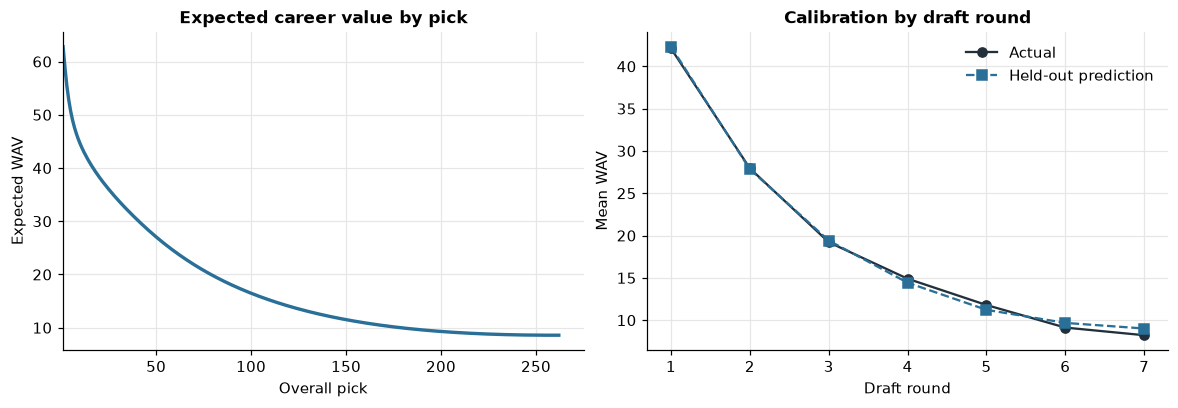

In [11]:
picks = outcomes.eligible_picks(scored)
with threadpool_limits(limits=1):
    graded = outcomes.grade_picks(picks)
    curve = outcomes.expected_curve(picks)
    simple_benchmark = outcomes.grade_picks(picks, flexible=False)

n_recorded = graded["actual_wav"].notna().sum()
print(f"Expected WAV for {len(graded):,} picks. Actual WAV is recorded for {n_recorded:,}.")
by_round = outcomes.calibration(graded, "draft_round")
by_position = outcomes.calibration(graded, "grp")
by_class = outcomes.calibration(graded, "draft_year")

benchmark_figure = plots.value_benchmark(curve, by_round)
plt.show()

In [12]:
validation = pd.DataFrame({
    "Smooth benchmark": outcomes.accuracy(graded),
    "Log-linear benchmark": outcomes.accuracy(simple_benchmark),
}).T
validation_labels = {"MAE": "Mean absolute error", "RMSE": "Root mean squared error"}
display(validation.rename(columns=validation_labels).round(2).rename_axis("Held-out error (WAV)"))

calibration_checks = {
    "Draft round": by_round,
    "Position": by_position,
    "Draft class": by_class,
}
largest_errors = []
for grouping, table in calibration_checks.items():
    group = table["error"].abs().idxmax()
    largest_errors.append({
        "Grouped by": grouping,
        "Group": f"{group:g}" if isinstance(group, float) else group,
        "Mean actual WAV": table.loc[group, "actual"],
        "Mean expected WAV": table.loc[group, "expected"],
    })
print("Largest absolute difference between mean actual and mean expected WAV in each grouping")
display(pd.DataFrame(largest_errors).set_index("Grouped by").round(2))

,Mean absolute error,Root mean squared error
Held-out error (WAV),,
Smooth benchmark,14.05,19.20
Log-linear benchmark,14.09,19.26


Largest absolute difference between mean actual and mean expected WAV in each grouping


,Group,Mean actual WAV,Mean expected WAV
Grouped by,,,
Draft round,7,8.22,9.01
Position,IOL,23.88,23.94
Draft class,2006,23.99,20.54


## 6. Career value relative to draft position

We subtract each player's expected WAV from actual WAV. A positive difference means the player produced more career value than the benchmark expected for that pick. We compare the average difference for each outlier group with the average for typical prospects.

The intervals come from 4,000 bootstrap resamples of draft classes. We resample players from the same class together and use the original held-out predictions in each resample.

,Picks,WAV recorded,Mean actual,Mean expected,Mean excess WAV,Gap vs. typical
Prospect group,,,,,,
Favorable outlier,79,77,25.62,25.74,-0.11,-0.11
Unusual build,87,82,19.67,20.85,-1.18,-1.18
Unfavorable outlier,37,33,12.09,13.27,-1.17,-1.17
Typical,4323,4010,20.41,20.41,-0.00,0.00


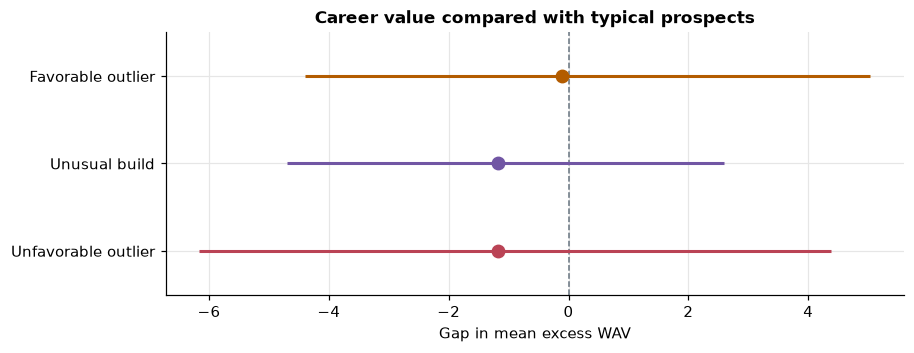

In [13]:
career = outcomes.career_summary(graded)
career_table = career[["eligible", "recorded", "actual", "expected", "excess", "gap"]].rename(
    index=plots.TYPE_LABEL, columns={
        "eligible": "Picks",
        "recorded": "WAV recorded",
        "actual": "Mean actual",
        "expected": "Mean expected",
        "excess": "Mean excess WAV",
        "gap": "Gap vs. typical",
    }
)
display(career_table.round(2).rename_axis("Prospect group"))

career_figure = plots.career_value_gaps(career)
plt.show()

## 7. Sensitivity checks

We repeat the career-value comparison for older draft classes, with blank WAV set to zero, and with a simpler benchmark that uses linear terms for log pick and draft year. We also vary the share of prospects flagged within each position and rerun the analysis using Combine information alone to assign position groups. For the last check, we use measurements to split broad position labels. We continue to use draft records to link prospects to their picks.

In [14]:
with threadpool_limits(limits=1):
    combine_only = prepare.build_sample(raw, use_pro_positions=False).prospects
    combine_only = detect.score_prospects(features.adjust_drills(combine_only))
    scenarios = {
        "Main analysis": graded,
        f"Classes through {outcomes.OLDER_LAST_CLASS}": outcomes.grade_picks(
            outcomes.eligible_picks(scored, outcomes.OLDER_LAST_CLASS)
        ),
        "Blank WAV set to zero": outcomes.grade_picks(picks, missing_as_zero=True),
        "Log-linear benchmark": simple_benchmark,
        "Positions from Combine data": outcomes.grade_picks(outcomes.eligible_picks(combine_only)),
    }

for share in (0.025, 0.10):
    flagged = graded["md_pct"].gt(1 - share)
    scenarios[f"Top {share:.1%} within position"] = graded.assign(
        utype=detect.unicorn_type(flagged, graded["ath_z"])
    )

gap_labels = {
    "recorded": "Favorable outliers",
    "gap": "Gap vs. typical",
    "lower": "95% CI lower",
    "upper": "95% CI upper",
}
sensitivity = outcomes.favorable_gaps(scenarios)
display(sensitivity.rename(columns=gap_labels).round(2).rename_axis("Analysis"))

influence = outcomes.individual_influence(graded)
influential = influence.iloc[0]
print(
    f"Removing {influential['player_name']} produces the largest single-player change "
    f"in the favorable-outlier gap ({influential['change_in_gap']:+.2f} WAV)."
)

combine_selection = outcomes.draft_selection(
    combine_only.loc[combine_only["season"].le(outcomes.LAST_DRAFT_CLASS)]
).reindex(detect.TYPES)
favorable, typical = combine_selection.loc["Freak"], combine_selection.loc["Typical"]
print(
    "Using Combine positions alone, favorable outliers and typical prospects were drafted "
    f"{favorable['draft_rate']:.0%} and {typical['draft_rate']:.0%} of the time, "
    f"with median picks of {favorable['median_pick']:g} and {typical['median_pick']:g}."
)

,Favorable outliers,Gap vs. typical,95% CI lower,95% CI upper
Analysis,,,,
Main analysis,77,-0.11,-4.39,5.04
Classes through 2018,67,-0.44,-5.24,5.40
Blank WAV set to zero,79,0.36,-3.64,5.17
Log-linear benchmark,77,-0.50,-4.83,4.72
Positions from Combine data,76,0.19,-4.15,5.29
Top 2.5% within position,37,1.17,-7.72,9.69
Top 10.0% within position,143,1.51,-2.14,5.67


Removing JaMarcus Russell produces the largest single-player change in the favorable-outlier gap (+0.81 WAV).
Using Combine positions alone, favorable outliers and typical prospects were drafted 89% and 67% of the time, with median picks of 68.5 and 108.


### Early and late rounds

We compare the first two rounds with rounds 3 through 7 to see whether the overall result hides a difference by draft stage. The estimates point in opposite directions, and both intervals include zero. We pool positions because each position has at most ten favorable outliers with recorded WAV.

In [15]:
early = graded["draft_round"].le(2)
round_groups = {
    "Rounds 1–2": graded.loc[early],
    "Rounds 3–7": graded.loc[~early],
}
round_gaps = outcomes.favorable_gaps(round_groups)
display(round_gaps.rename(columns=gap_labels).round(2).rename_axis("Draft rounds"))

,Favorable outliers,Gap vs. typical,95% CI lower,95% CI upper
Draft rounds,,,,
Rounds 1–2,37,3.55,-4.34,12.68
Rounds 3–7,40,-3.45,-7.60,1.31


### Steals and busts

We also compare how often players finish well above or below expected WAV. For a cutoff of 10 WAV, a steal finishes at least 10 above expectations and a bust finishes at least 10 below. We report rates at three cutoffs because the choice affects how many picks fall in each category. A late pick with a low expected WAV has less room to fall 10 points below expectations.

In [16]:
rates = outcomes.grade_rates(graded)
rates_table = rates.reset_index()
rates_table["utype"] = rates_table["utype"].map(plots.TYPE_LABEL)
rates_table = rates_table.rename(columns={
    "utype": "Prospect group", "steal": "Steal rate (%)", "bust": "Bust rate (%)",
}).set_index(["WAV cutoff", "Prospect group"])
display((100 * rates_table).round(1))

Steal rate (%)  Bust rate (%)
WAV cutoff Prospect group                                    
5          Favorable outlier              40.3           48.1
           Unusual build                  25.6           50.0
           Unfavorable outlier            18.2           51.5
           Typical                        29.6           48.4
10         Favorable outlier              27.3           37.7
           Unusual build                  22.0           30.5
           Unfavorable outlier            12.1           30.3
           Typical                        22.6           30.4
20         Favorable outlier              15.6           11.7
           Unusual build                  11.0           13.4
           Unfavorable outlier             6.1            6.1
           Typical                        13.1            8.2

## 8. Findings

Favorable athletic outliers were drafted more often than typical prospects (88% versus 67%). Among those drafted, their median pick was 72, compared with 108 for typical prospects. The draft-rate gap was similar when we assigned positions using Combine information alone.

The favorable outliers averaged 0.1 WAV less than typical prospects after accounting for their draft picks, positions, and draft classes. The 95% interval ranged from 4.4 WAV less to 5.0 WAV more. The interval included zero in every sensitivity check. The size and direction of any career-value advantage remain uncertain.

Actual WAV is missing for 324 eligible picks. The main career comparison uses recorded outcomes, and its interpretation depends on how well career WAV measures contributions across positions. The draft-selection results apply to Combine prospects with the measurements needed for scoring.

## Export results

Running the notebook saves the player-level grades, summary tables, and figures in the outputs directory.

In [17]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

player_results = graded[[
    "player_name", "draft_year", "draft_ovr", "draft_round", "grp", "utype",
    "actual_wav", "expected_wav", "excess_wav",
]].copy()
player_results["utype"] = player_results["utype"].map(plots.TYPE_LABEL)
grade = pd.Series("Within 10 WAV", index=player_results.index, dtype="string")
grade = grade.mask(player_results["excess_wav"].ge(10), "Steal")
grade = grade.mask(player_results["excess_wav"].le(-10), "Bust")
player_results["grade_at_10_wav"] = grade.where(player_results["excess_wav"].notna())
player_results.to_csv(output_dir / "player_career_value.csv", index=False)

tables = {
    "draft_selection": selection.rename(index=plots.TYPE_LABEL),
    "draft_selection_combine_positions": combine_selection.rename(index=plots.TYPE_LABEL),
    "dash_coverage": coverage,
    "expected_wav_curve": curve.set_index("draft_ovr"),
    "career_value_by_group": career.rename(index=plots.TYPE_LABEL),
    "benchmark_validation": validation,
    "benchmark_calibration": pd.concat(calibration_checks, names=["Grouping", "Group"]),
    "sensitivity": sensitivity,
    "career_value_by_draft_stage": round_gaps,
    "steal_bust_rates": rates_table,
}
for filename, table in tables.items():
    table.to_csv(output_dir / f"{filename}.csv")

figures = {
    "draft_selection": selection_figure,
    "expected_wav": benchmark_figure,
    "career_value_gaps": career_figure,
}
for filename, figure in figures.items():
    figure.savefig(output_dir / f"{filename}.png", dpi=180)